# Piste 6 — Prévoir la demande en pièces détachées

**Question métier :** combien de pièces stocker pour éviter les ruptures sans accumuler de stock dormant ?

> ✅ **Données réelles** : ventes mensuelles de 2 674 pièces automobiles d'un constructeur américain, 1998-2002 (jeu public de Rob Hyndman, package R `expsmooth`). Ce sont des voitures, pas des camions : on démontre la méthode sur une demande réelle.

Environ **75 % des mois n'ont aucune vente** : c'est une **demande intermittente**, typique des pièces détachées. On apprend sur 39 mois et on évalue sur les 12 derniers.

Pièces gardées : 2509 | mois : 51
Mois sans aucune vente : 74.9 %


                               erreur moyenne (pièces/an)  pièces en rupture (%)  unités en rupture  stock dormant (unités)
méthode                                                                                                                    
Naïf (dernier mois × 12)                              7.5                   56.8             8001.0                 10853.0
Moyenne 12 derniers mois                              3.7                   33.0             3797.0                  5488.0
Croston                                               5.8                   27.1             5091.0                  9803.0
IA (gradient boosting global)                         3.5                   24.1             3588.0                  5620.0


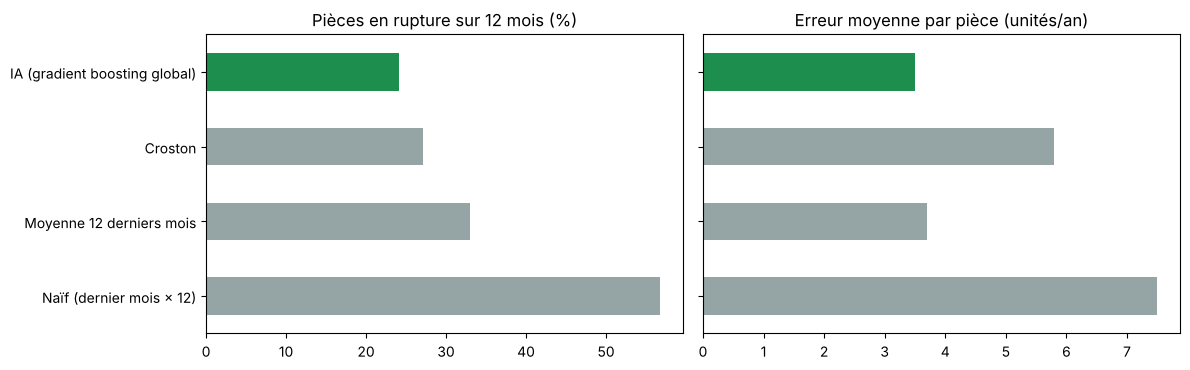

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

# ---------- DONNÉES RÉELLES : ventes mensuelles de 2 674 pièces (1998-2002) ----------
ventes = pd.read_csv("data/carparts_ventes_mensuelles.csv", index_col="mois", parse_dates=True)
ventes = ventes.dropna(axis=1)                       # on garde les pièces sans trou
print("Pièces gardées :", ventes.shape[1], "| mois :", ventes.shape[0])
print("Mois sans aucune vente :", round((ventes == 0).mean().mean() * 100, 1), "%")

Y = ventes.values.T                                   # une ligne par pièce
FIN_TRAIN = 39                                        # 39 mois pour apprendre, 12 pour tester
reel = Y[:, FIN_TRAIN:].sum(axis=1)                   # demande réelle des 12 derniers mois

def croston(y, alpha=0.1):
    """Méthode de référence pour la demande intermittente (beaucoup de zéros)."""
    z, p, q = None, None, 1
    for v in y:
        if v > 0:
            if z is None:
                z, p = v, q
            else:
                z += alpha * (v - z)
                p += alpha * (q - p)
            q = 1
        else:
            q += 1
    return 0.0 if z is None else z / p

def variables(h):
    """Résumé de l'historique d'une pièce, utilisé par le modèle d'IA."""
    nz = np.nonzero(h)[0]
    return [h[-3:].mean(), h[-6:].mean(), h[-12:].mean(), h.mean(), h[-12:].std(),
            (h[-12:] == 0).mean(), len(h) - 1 - nz[-1] if len(nz) else len(h), croston(h)]

# ---------- 3 méthodes classiques ----------
hist = Y[:, :FIN_TRAIN]
prev = {
    "Naïf (dernier mois × 12)": hist[:, -1] * 12,
    "Moyenne 12 derniers mois": hist[:, -12:].mean(axis=1) * 12,
    "Croston": np.array([croston(h) for h in hist]) * 12,
}

# ---------- Modèle d'IA global : apprend sur toutes les pièces à la fois ----------
X_app, y_app = [], []
for t in range(12, FIN_TRAIN - 12 + 1):              # fenêtres entièrement dans le passé
    for h in Y[:, :t + 12]:
        X_app.append(variables(h[:t])); y_app.append(h[t:t + 12].sum())
ia = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, random_state=42)
ia.fit(np.array(X_app), np.array(y_app))
prev["IA (gradient boosting global)"] = ia.predict(np.array([variables(h) for h in hist]))

# ---------- Évaluation : précision et impact sur le stock ----------
lignes = []
for nom, p in prev.items():
    stock = np.ceil(p)                                # on stocke la prévision arrondie
    lignes.append({
        "méthode": nom,
        "erreur moyenne (pièces/an)": np.abs(p - reel).mean(),
        "pièces en rupture (%)": (reel > stock).mean() * 100,
        "unités en rupture": np.clip(reel - stock, 0, None).sum(),
        "stock dormant (unités)": np.clip(stock - reel, 0, None).sum(),
    })
res = pd.DataFrame(lignes).set_index("méthode").round(1)
print(res.to_string())

# ---------- Graphique pour le rapport ----------
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
couleurs = ["#95a5a6", "#95a5a6", "#95a5a6", "#1e8e4e"]
res["pièces en rupture (%)"].plot(kind="barh", ax=ax[0], color=couleurs)
ax[0].set_title("Pièces en rupture sur 12 mois (%)"); ax[0].set_ylabel("")
res["erreur moyenne (pièces/an)"].plot(kind="barh", ax=ax[1], color=couleurs)
ax[1].set_title("Erreur moyenne par pièce (unités/an)"); ax[1].set_ylabel(""); ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig("images/pieces_comparaison.png", dpi=150); plt.show()


## Conclusions
- Le modèle d'IA global (gradient boosting appris sur toutes les pièces à la fois) a la plus petite erreur et réduit les pièces en rupture d'environ **33 % à 24 %** par rapport à la moyenne des 12 derniers mois, pour un stock dormant équivalent.
- Croston, pourtant la référence théorique pour la demande intermittente, fait moins bien ici : il faut **tester plusieurs méthodes sur ses propres données**.